In [1]:
# 공용 자료와 모듈 경로를 현재 저장소에서 찾는다.
from pathlib import Path
import os, sys

_course_name = "17_rag"
_start = Path.cwd().resolve()
_candidates = [p for base in (_start, *_start.parents) for p in (base, base / _course_name)]
PROJECT_ROOT = next((p for p in _candidates if p.name == _course_name and p.is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"17_Study 안에서 실행해 주세요: {_course_name}")
os.chdir(PROJECT_ROOT / "DAY2_261006")
sys.path.insert(0, str(PROJECT_ROOT))

import os
import warnings
warnings.filterwarnings('ignore', message = ".*Glyph.*")
import gc, json, random, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

QUICK = True

BASE = Path.cwd()
ASSETS = PROJECT_ROOT / 'assets'
DATA = PROJECT_ROOT / 'data' / 'knowledge'
WORK = BASE / 'work'
for d in ('models', 'chroma', 'images'):
    (WORK / d).mkdir(parents = True, exist_ok = True)

if torch.cuda.is_available():
    DEVICE = 'cuda'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'

IMG_TYPE = torch.float16 if DEVICE in ('cuda', 'mps') else torch.float32

installed = {f.name for f in font_manager.fontManager.ttflist}
for name in ('AppleGothic', 'Malgun Gothic', 'NanumGothic'):
    if name in installed:
        plt.rcParams['font.family'] = name
        break

plt.rcParams['axes.unicode_minus'] = False


In [2]:
def set_seed(seed = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def free_memory():
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

def show_images(images, titles = None, cols = None, size = 3.2):
    cols = cols or len(images)
    rows = (len(images) + cols -1) // cols
    fig, axes = plt.subplots(rows, cols, figsize = (size * cols, size * rows), squeeze = False)
    for ax in axes.ravel():
        ax.axis('off')

    for i, im in enumerate(images):
        axes.ravel()[i].imshow(im)
        if titles:
            axes.ravel()[i].set_title(titles[i], fontsize = 10)

    plt.tick_params()
    plt.show()

set_seed(42)
print(DEVICE, QUICK)
print(BASE)

cuda True
C:\Users\KDS-22\Documents\17_Study\17_rag\DAY2_261006


In [3]:
from transformers import AutoTokenizer, AutoModel

EMB_NAME = 'intfloat/multilingual-e5-small'
tok = AutoTokenizer.from_pretrained(EMB_NAME)
emb_model = AutoModel.from_pretrained(EMB_NAME).eval().to(DEVICE)

sentences = ['나는 강아지를 정말 좋아합니다.', '금요일은 행복한 날이에요']
enc = tok(sentences, padding = True, truncation = True, return_tensors = 'pt')

print(enc['input_ids'])
for i in range(len(sentences)):
    print(tok.convert_ids_to_tokens(enc['input_ids'][i]))
print(enc['attention_mask'])



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tensor([[     0,  37231,  13564,   3222,  49067,  34682,  67738,   8642,      5,
              2],
        [     0,  36527,   5144,   1599,    697, 169384,  21858, 190278,      2,
              1]])
['<s>', '▁나는', '▁강', '아', '지를', '▁정말', '▁좋아', '합니다', '.', '</s>']
['<s>', '▁금', '요', '일', '은', '▁행복한', '▁날', '이에요', '</s>', '<pad>']
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 0]])


In [4]:
with torch.no_grad():
    out = emb_model(**enc.to(DEVICE))

emb = out.last_hidden_state

print(tuple(emb.shape))
print(emb[0, 0, :6].cpu().numpy().round(3))

(2, 10, 384)
[ 0.166 -0.037 -0.112 -0.297  0.428 -0.065]


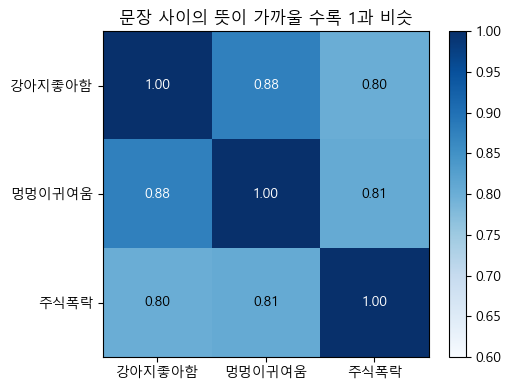

In [5]:
import torch.nn.functional as F

def embed(texts, prefix = 'query', batch_size = 32):
    vectors = []
    for i in range(0, len(texts), batch_size):
        batch = [prefix + t for t in texts[i:i + batch_size]]
        enc = tok(batch, padding = True, truncation=True, max_length=512, return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            hidden = emb_model(**enc).last_hidden_state
        mask = enc['attention_mask'].unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        vectors.append(F.normalize(pooled, p = 2, dim = 1).cpu())
    return torch.cat(vectors)

test = ['나는 강아지를 정말 좋아해요.',
        '우리 집 멍멍이가 세상에서 제일 귀여워요.',
        '주식 시장이 크게 폭락했습니다.']

vecs = embed(test)
sim = vecs @vecs.T

fig, ax = plt.subplots(figsize = (5.2, 4))
im = ax.imshow(sim.numpy(), cmap = 'Blues', vmin = 0.6, vmax = 1)
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(['강아지좋아함', '멍멍이귀여움', '주식폭락'])
ax.set_yticklabels(['강아지좋아함', '멍멍이귀여움', '주식폭락'])

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha = 'center', va = 'center', color = 'white' if sim[i, j] > 0.85 else 'black')

ax.set_title('문장 사이의 뜻이 가까울 수록 1과 비슷')

plt.colorbar(im)
plt.tight_layout()
plt.show()


In [6]:
from torchvision import transforms, models

img = Image.open(ASSETS / 'puppy.jpg').convert('RGB')

weights = models.ResNet18_Weights.DEFAULT
resnet = models.resnet18(weights=weights).eval()
labels = weights.meta['categories']

batch = weights.transforms()(img).unsqueeze(0)

with torch.no_grad():
    logits = resnet(batch)
probs = torch.softmax(logits, dim=1)[0]
top_p, top_i = probs.topk(5)

for p, i in zip(top_p, top_i):
    print(f'{labels[i]:25s}{p:.1%}')

entropy = -(probs * torch.log(probs + 1e-10)).sum()
print(f'entropy: {entropy:.3f}')

Labrador retriever       23.9%
Sealyham terrier         18.3%
tennis ball              11.6%
Great Pyrenees           11.6%
golden retriever         7.6%
entropy: 2.658


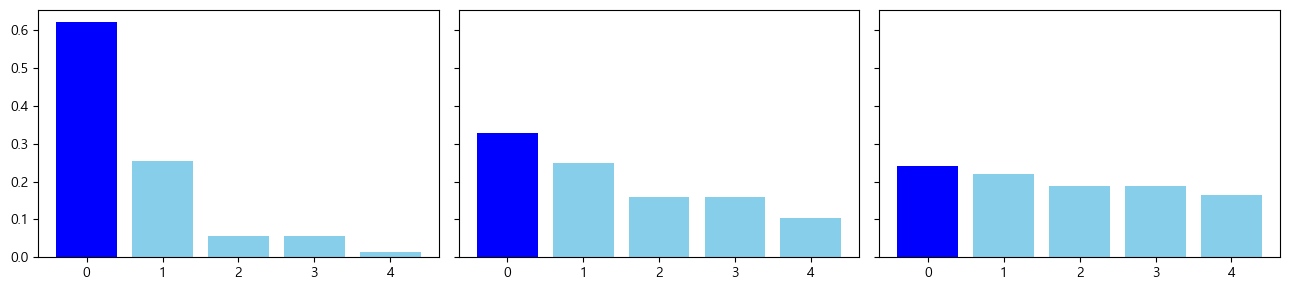

In [7]:
top_logits = logits[0].topk(5).values
fig, axes= plt.subplots(1, 3, figsize=(13, 3), sharey = True)

for ax, T in zip(axes, (0.3, 1.0, 3.0)):
    p = torch.softmax(top_logits / T, dim=0)
    ax.bar(range(5), p.numpy(), color = ['blue'] + ['skyblue'] * 4)
plt.tight_layout(); plt.show()

In [8]:
from huggingface_hub import HfApi, hf_hub_download, ModelCard

api = HfApi()
try:
    info = api.model_info(EMB_NAME)
    print(info.id)
    print(info.pipeline_tag)
    print(info.downloads) 
    print(info.tags)
    for m in api.list_models(filter = 'text-classification', sort = 'downloads', limit = 5):
        print(m.id)
        
except Exception as e:
    print('Failed')

intfloat/multilingual-e5-small
sentence-similarity
11268724
['sentence-transformers', 'pytorch', 'onnx', 'safetensors', 'openvino', 'bert', 'mteb', 'Sentence Transformers', 'sentence-similarity', 'multilingual', 'af', 'am', 'ar', 'as', 'az', 'be', 'bg', 'bn', 'br', 'bs', 'ca', 'cs', 'cy', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu', 'fa', 'fi', 'fr', 'fy', 'ga', 'gd', 'gl', 'gu', 'ha', 'he', 'hi', 'hr', 'hu', 'hy', 'id', 'is', 'it', 'ja', 'jv', 'ka', 'kk', 'km', 'kn', 'ko', 'ku', 'ky', 'la', 'lo', 'lt', 'lv', 'mg', 'mk', 'ml', 'mn', 'mr', 'ms', 'my', 'ne', 'nl', 'no', 'om', 'or', 'pa', 'pl', 'ps', 'pt', 'ro', 'ru', 'sa', 'sd', 'si', 'sk', 'sl', 'so', 'sq', 'sr', 'su', 'sv', 'sw', 'ta', 'te', 'th', 'tl', 'tr', 'ug', 'uk', 'ur', 'uz', 'vi', 'xh', 'yi', 'zh', 'arxiv:2402.05672', 'arxiv:2108.08787', 'arxiv:2104.08663', 'arxiv:2210.07316', 'license:mit', 'model-index', 'eval-results', 'text-embeddings-inference', 'endpoints_compatible', 'region:us']


cross-encoder/ms-marco-MiniLM-L6-v2
BAAI/bge-reranker-v2-m3
cross-encoder/ms-marco-MiniLM-L4-v2
ProsusAI/finbert
BAAI/bge-reranker-base


In [9]:
try:
    card = ModelCard.load(EMB_NAME)
    print(card.text[:500].strip())
except Exception as e:
    print('Failed')
cfg = json.load(open(hf_hub_download(EMB_NAME, 'config.json')))
for k in ('model_type', 'num_hidden_layers', 'hidden_size', 'num_attention_heads', 'vocab_size', 'max_position_embeddings'):
    print(cfg[k])

## Multilingual-E5-small

[Multilingual E5 Text Embeddings: A Technical Report](https://arxiv.org/pdf/2402.05672).
Liang Wang, Nan Yang, Xiaolong Huang, Linjun Yang, Rangan Majumder, Furu Wei, arXiv 2024

This model has 12 layers and the embedding size is 384.

## Usage

Below is an example to encode queries and passages from the MS-MARCO passage ranking dataset.

```python
import torch.nn.functional as F

from torch import Tensor
from transformers import AutoTokenizer, AutoModel


def average


bert
12
384
12
250037
512


In [10]:
from transformers import pipeline, set_seed

en_sentiment = pipeline('sentiment-analysis',
    model = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english',
    device = DEVICE)
for s in ['I love working with transformers!', 'This was the worst meeting ever']:
    print(s, en_sentiment(s)[0])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

I love working with transformers! {'label': 'POSITIVE', 'score': 0.999541163444519}
This was the worst meeting ever {'label': 'NEGATIVE', 'score': 0.999785840511322}


In [11]:
generator = pipeline('text-generation', model = 'gpt2', device = DEVICE)
prompt = 'The future of AI is'

for temp in (0.3, 1.5):
    set_seed(7)
    out = generator(prompt, max_new_tokens = 30,
                    do_sample = True, temperature = temp, top_k = 50)
    print(temp, out[0]['generated_text'])

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'do_sample', 'top_k', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[transformers] Both `max_new_tokens` (=30) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[transformers] Both `max_new_tokens` (=30) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


0.3 The future of AI is not yet clear. But it is possible that AI will be able to solve many problems, and that it will be able to solve many problems at once


1.5 The future of AI is not always on-watch; it's changing how technology is perceived today and, at the end of that era it may just break down into smaller and


In [12]:
from transformers import AutoModelForSequenceClassification

name = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
tk = AutoTokenizer.from_pretrained(name)
clf = AutoModelForSequenceClassification.from_pretrained(name).eval()

text = 'The club meeting was surprisingly fun!'
enc  = tk(text, return_tensors = 'pt')
with torch.no_grad():
    logits = clf(**enc).logits

probs = torch.softmax(logits, dim= -1)[0]

print(tk.convert_ids_to_tokens(enc['input_ids'][0]))
print(logits[0].numpy().round(2))
print(probs.numpy().round(3))
print(clf.config.id2label, clf.config.id2label[int(probs.argmax())])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

['[CLS]', 'the', 'club', 'meeting', 'was', 'surprisingly', 'fun', '!', '[SEP]']
[-4.28  4.61]
[0. 1.]
{0: 'NEGATIVE', 1: 'POSITIVE'} POSITIVE


In [13]:
bert_tok = AutoTokenizer.from_pretrained('bert-base-uncased')
print(bert_tok.tokenize('Thr ultramarathoner prequlified for the immunohistochemistry conference.'))
for s in ['인공지능비서', '머신러닝', '동아리의해커톤']:
    print(f'다국어 e5 :{s!r:14} ->', tok.tokenize(s))

['th', '##r', 'ultra', '##mara', '##th', '##one', '##r', 'pre', '##qu', '##li', '##fied', 'for', 'the', 'im', '##mun', '##oh', '##isto', '##chemist', '##ry', 'conference', '.']
다국어 e5 :'인공지능비서'       -> ['▁인공지능', '비', '서']
다국어 e5 :'머신러닝'         -> ['▁머', '신', '러', '닝']
다국어 e5 :'동아리의해커톤'      -> ['▁동', '아리', '의', '해', '커', '톤']


In [14]:
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

ID2LABEL = {0: '부정', 1: '긍정'}

raw = load_dataset(
    'csv',
    data_files={
        'train': 'https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt',
        'test': 'https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt',
    },
    delimiter='\t',
)
train_raw = raw['train'].filter(lambda row: row['document'] is not None)
eval_raw = raw['test'].filter(lambda row: row['document'] is not None)
if QUICK:
    train_raw = train_raw.shuffle(seed=42).select(range(min(2000, len(train_raw))))
    eval_raw = eval_raw.shuffle(seed=42).select(range(min(500, len(eval_raw))))

def tokenize_batch(batch):
    return tok(batch['document'], truncation = True, max_length = 64)

train_ds = train_raw.map(tokenize_batch, batched = True, remove_columns = ['id', 'document'])
eval_ds = eval_raw.map(tokenize_batch, batched = True, remove_columns = ['id', 'document'])

def accuracy(eval_pred):
    logits, y = eval_pred
    return {'accuracy': float((np.argmax(logits, axis= -1) == y).mean())}

set_seed(42)
ft_model = AutoModelForSequenceClassification.from_pretrained(EMB_NAME, num_labels = 2, id2label = ID2LABEL, label2id = {v: k for k, v in ID2LABEL.items()})

args = TrainingArguments(
    output_dir=str(WORK / 'ckpt'),
    num_train_epochs= 2 if QUICK else 3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate = 5e-5,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps = 20,
    report_to='none',
    seed=42
)

trainer = Trainer(model = ft_model, args=args, train_dataset = train_ds, eval_dataset=eval_ds, data_collator=DataCollatorWithPadding(tok), compute_metrics=accuracy)

base_acc = trainer.evaluate()['eval_accuracy']
print(f'파인튜닝전 정확도: {base_acc:.1%}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: intfloat/multilingual-e5-small
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training Loss,Validation Loss,Epoch,Accuracy
No log,0.695295,0,0.468000


파인튜닝전 정확도: 46.8%


In [15]:
t0 = time.time()
trainer.train()
print(f'학습시간{time.time() - t0:0f}초')

ft_acc = trainer.evaluate()['eval_accuracy']
print(f'파인튜닝 후 정확도: {ft_acc:.1%}')

Epoch,Training Loss,Validation Loss,Accuracy
1,0.565970,0.534543,0.756000
2,0.495759,0.502096,0.774000


학습시간9.413514초


Training Loss,Validation Loss,Epoch,Accuracy
0.495759,0.502096,2,0.774000


파인튜닝 후 정확도: 77.4%


In [16]:
import torch.nn as nn

class PromptTuningClassifier(nn.Module):
    def __init__(self, model_name, num_virtual_tokens = 20):
        super().__init__()
        self.backbone = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels = 2, id2label = ID2LABEL,
            label2id = {v: k for k, v in ID2LABEL.items()})
        self.backbone.requires_grad_(False)
        for p in self.backbone.classifier.parameters():
            p.requires_grad_(True)
        self.n = num_virtual_tokens
        word_emb = self.backbone.get_input_embeddings()
        init_ids = torch.randint(1000, 2000, (num_virtual_tokens,))
        self.prompt = nn.Parameter(word_emb(init_ids).detach().clone().unsqueeze(0))

    def forward(self, input_ids, attention_mask, labels = None):
        b = input_ids.shape[0]
        word_emb = self.backbone.get_input_embeddings()(input_ids)
        input_embeds = torch.cat([self.prompt.expand(b, -1, -1), word_emb], dim = 1)
        mask = torch.cat([torch.ones(b, self.n, device=attention_mask.device,
                                     dtype = attention_mask.dtype), attention_mask], dim = 1)
        return self.backbone(inputs_embeds = input_embeds, attention_mask = mask, labels = labels)
set_seed(42)
pt_model = PromptTuningClassifier(EMB_NAME).to(DEVICE)
n_train = sum(p.numel() for p in pt_model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in pt_model.parameters())
print('전체 파라미터 : ', n_total)
print('학습대상 : ', n_train)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: intfloat/multilingual-e5-small
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


전체 파라미터 :  117662210
학습대상 :  8450


In [17]:
from torch.utils.data import DataLoader

collate = DataCollatorWithPadding(tok)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collate)
eval_loader = DataLoader(eval_ds, batch_size=64, collate_fn=collate)

def evaluate_pt(model):
    model.eval()
    correct = 0
    with torch.no_grad():
        for b in eval_loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            y = b.pop('labels')
            correct += (model(b['input_ids'], b['attention_mask']).logits.argmax(-1) == y).sum().item()

    return correct / len(eval_ds)

PT_EPOCHS = 4 if QUICK else 8
opt = torch.optim.AdamW([p for p in pt_model.parameters() if p.requires_grad], lr = 2e-2)
pt_losses = []
for epoch in range(PT_EPOCHS):
    pt_model.train()
    total = 0
    for b in train_loader:
        b = {k:v.to(DEVICE) for k, v in b.items()}
        y = b.pop('labels')
        loss = pt_model(b['input_ids'], b['attention_mask'], labels = y).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(pt_model.parameters(), 1.0)
        opt.step()
        opt.zero_grad()
        total += loss.item()
    pt_losses.append(total / len(train_loader))
    print(epoch + 1, pt_losses, evaluate_pt(pt_model))
pt_acc = evaluate_pt(pt_model)
print(pt_acc)

1 [0.6737666517969162] 0.748


2 [0.6737666517969162, 0.5829651123947568] 0.72


3 [0.6737666517969162, 0.5829651123947568, 0.5743720791642628] 0.722


4 [0.6737666517969162, 0.5829651123947568, 0.5743720791642628, 0.5386735352258833] 0.754


0.754


In [18]:
import requests

OLLAMA_URL = 'http://localhost:11434'
LLM_MODEL = 'gemma3:4b'
_ollama_proc = None

def ollama_alive():
    try:
        return requests.get(f"{OLLAMA_URL}/api/tags", timeout = 2).ok
    except requests.RequestException:
        return False

def ensure_ollama(model = LLM_MODEL):
    global _ollama_proc
    if not ollama_alive():
        if shutil.which('ollama') is None:
            raise RuntimeError('올라마가 설치되어 있지 않아요.')
        print('올라마 서버를 켜는 중')
        log = open(WORK / 'ollama_server.log', 'w')
        _ollama_proc = subprocess.Popen(['ollama', 'serve'], stdout = log, stderr = log, start_new_session= True)

        for _ in range(60):
            if ollama_alive():
                break
            time.sleep(0.5)
        else:
            raise RuntimeError('올라마 서버가 꺼져있어요. log확인')

    have = [m['name'] for m in requests.get(f"{OLLAMA_URL}/api/tags").json().get('models', [])]
    if model not in have and f'{model}:latest' not in have:
        print(f'모델 {model} 다운로드 받는 중 (처음 한번만 오래 걸림)')
        last = -1
        with requests.post(f'{OLLAMA_URL}/api/pull', json = {'model': model}, stream = True) as r:
            for line in r.iter_lines():
                if not line:
                    continue
                d = json.loads(line)
                if d.get('total') and d.get('completed'):
                    pct = int(d['completed'] / d['total'] * 100)
                    if pct // 10 != last // 10:
                        print(f"{pct}%", end = " ", flush = True)
                        last = pct
    
ensure_ollama()

In [19]:
def chat(messages, temperature = 0.7, model = LLM_MODEL, fmt = None, max_tokens = None, seed = None):
    options = {'temperature': temperature}
    if max_tokens:
        options ['num_predict'] = max_tokens
    if seed is not None:
        options['seed'] = seed
    payload = {'model': model, 'messages': messages, 'stream': False, 'options': options, 'keep_alive': '30m'}

    if fmt:
        payload['format'] = fmt
    r = requests.post(f"{OLLAMA_URL}/api/chat", json = payload, timeout = 600)
    r.raise_for_status()
    return r.json()['message']['content']

print(chat([{'role': 'user', 'content': '안녕하세요. 당신은 누구입니까? 한 문장으로 답해주세요.'}]))

저는 Google에서 훈련한 대규모 언어 모델입니다.


In [20]:
MOA_SYSTEM = ('너는 대학 AI 입문 동아리, "모아"의 친절한 AI 비서 "모아"야.'
              '항상 한국어로, 존댓말로, 3문장 이내로 짧게 따뜻하게 대답해줘.')

q = '동아리에 처음 왔는데, 너무 떨려요. 어떡하죠?'
print('System 없이:', chat([{'role': 'user', 'content': q}], max_tokens = 120).strip()[:200].replace('\n', ' '))
print('성격 부여 후:', chat([{'role': 'system', 'content': MOA_SYSTEM}, {'role': 'user', 'content': q}]))

System 없이: 동아리에 처음 오셨다니, 정말 떨리시겠어요! 새로운 환경에 대한 기대감과 설렘은 당연한 감정이죠. 너무 걱정하지 마시고, 제가 몇 가지 도움을 드릴게요.  **1. 떨림을 받아들이고 편안하게:**  *   **괜찮다는 것을 기억하세요:** 처음 오는 사람이라면 누구든 떨리는 건 자연스러운 일이에요. 스스로를 너무 자책하거나 불안해하지 마세요. *   **숨


성격 부여 후: 안녕하세요, 처음 오셨다니 정말 반갑습니다! 😊 혹시 긴장되시는 것 같은데, 모아는 여러분이 편안하게 동아리에 적응하실 수 있도록 돕고 싶습니다. 

모아와 함께 즐겁게 AI를 배우고 성장하는 시간을 보내시길 바랍니다. 궁금한 점이 있다면 언제든지 편하게 말씀해주세요!


In [21]:
class MoaChat:
    def __init__(self, system = MOA_SYSTEM, temperature = 0.7):
        self.messages = [{'role': 'system', 'content': system}]
        self.temperature = temperature

    def say(self, text):
        self.messages.append({'role': 'user', 'content': text})
        answer = chat(self.messages, temperature = self.temperature)
        self.messages.append({'role': 'assistant', 'content': answer})
        return answer

bot = MoaChat()
print(bot.say('저는 피카츄고, 파이썬을 처음 배워요.'))
print(bot.say('제 이름이 뭐였죠?'))
print(chat([{'role': 'system', 'content': MOA_SYSTEM}, {'role':'user', 'content':'제 이름이 뭐였죠?'}]))

안녕하세요, 피카츄! 파이썬을 처음 배우신다니 정말 멋진데요. 
처음 배우는 것은 어렵지만, 꾸준히 노력하시면 분명 좋은 결과가 있을 거예요. 
모아가 항상 곁에서 도와드릴 테니 걱정 마세요!


피카츄님, 귀여운 이름이시네요! 혹시 기억이 잘 안 나셨다면 괜찮습니다. 
앞으로 모아와 함께 파이썬 공부하면서 더욱 즐겁게 지내시길 바랍니다. 😊


안녕하세요, 만나서 반갑습니다! 혹시 기억나시면 말씀해주시면 더욱 친근하게 소통할 수 있을 것 같아요. 😊


In [22]:
def chat_stream(messages, temperature = 0.7, model = LLM_MODEL):
    payload = {'model': model, 'messages': messages, 'stream': True, 'options': {'temperature': temperature}}
    parts = []
    with requests.post(f"{OLLAMA_URL}/api/chat", json = payload, stream = True, timeout = 600) as r:
        for line in r.iter_lines():
            if line:
                chunk = json.loads(line)
                parts.append(chunk['message']['content'])
    answer = ''.join(parts)
    print(answer)
    return answer
stream_answer = chat_stream([{'role': 'system', 'content': MOA_SYSTEM}, {'role':'user', 'content': '동아리 마스코트 이름을 지어준다면 어떤게 좋을까?'}])

안녕하세요, 회원님! 모아입니다. 

동아리 마스코트 이름을 짓는 건 정말 즐거운 고민이네요. 귀여운 로봇 느낌을 살려 "모아봇"이나 "알파" 같은 이름도 좋고, AI의 지혜로운 면모를 담아 "지혜" 또는 "루시"도 괜찮을 것 같습니다. 어떤 이름이 마음에 드시나요?


In [23]:
review = "해커톤 떄 간식은 맛있었는데, 와이파이가 자꾸만 끊겨서 프로젝트 제출을 못할 뻔 했어요. 그래도 팀원들 덕분에 즐거웠습니다."
sys_json = "후기를 읽고 JSON으로만 답해. 키: sentiment (긍정/부정/중립), topics(문자열 배열), complaint(불만 한줄, 없으면 빈 문자열)"
raw = chat([{'role' : 'system', 'content': sys_json}, {'role':'user', 'content': review}], temperature =0, fmt = 'json')
parsed = json.loads(raw)
print('구조화된 결과 :',json.dumps(parsed, ensure_ascii = False, indent = 2))
print('파이썬에서 바로 사용:',parsed['sentiment'], parsed['topics'])


구조화된 결과 : {
  "sentiment": "긍정",
  "topics": [
    "간식",
    "와이파이",
    "팀원"
  ],
  "complaint": "와이파이 끊김으로 프로젝트 제출 못할 뻔"
}
파이썬에서 바로 사용: 긍정 ['간식', '와이파이', '팀원']


In [24]:
ALL_REVIEWS = [review] + [
    "와이파이가 너무 느려서 실습 중간에 계속 멈췄어요.",
    "회장님이 질문마다 끝까지 설명해 줘서 감동받았습니다.",
    "모임 장소가 좁아서 사람이 많은 길은 앉을 자리가 없어요.",
    "마스코트 스티커가 너무 귀여워요! 노트북에 붙였어요."
]
numbered = '\n'.join(f"{i+1}. {r}" for i, r in enumerate(ALL_REVIEWS))
report = chat([
    {'role':'system', 'content':'너는 동아리 운영을 돕는 분석가야. 한국어로 답해줘.'},
    {'role': 'user', 'content': f"아래는 동아리 행사 후기 모음이야. 1. 잘한 점 2가지, 2.개선할 점 3가지를 각각 한줄로 정리해줘. {numbered}"}
], temperature = 0.3)
print(report)

## 동아리 행사 후기 분석 결과

**1. 해커톤 행사 분석**

*   **잘한 점:**
    *   맛있는 간식 제공
    *   팀원들과의 즐거운 분위기 조성
*   **개선할 점:**
    *   안정적인 와이파이 환경 구축
    *   프로젝트 제출 마감 시간 준수
    *   문제 발생 시 즉각적인 해결 방안 마련

**2. 와이파이 실습 행사 분석**

*   **잘한 점:** (없음 - 와이파이 문제 외에는 긍정적인 내용 없음)
*   **개선할 점:**
    *   실습 환경의 안정적인 와이파이 환경 확보
    *   실습 진행 중 발생하는 문제에 대한 신속한 대처

**3. 회장님 질의응답 행사 분석**

*   **잘한 점:**
    *   회장님의 상세하고 명확한 설명
    *   회장님에 대한 감사와 감동

**4. 모임 장소 분석**

*   **잘한 점:** (없음 - 모임 장소에 대한 긍정적인 언급 없음)
*   **개선할 점:**
    *   모임 규모에 적합한 넓은 모임 장소 확보
    *   사람이 많은 경우 좌석 부족 문제 해결 방안 마련

**5. 마스코트 스티커 행사 분석**

*   **잘한 점:**
    *   귀여운 마스코트 스티커 제공
    *   마스코트 스티커에 대한 높은 만족도


In [25]:
docs = {p.name:p.read_text(encoding = 'utf-8') for p in sorted(DATA.glob("*.txt"))}
print(list(docs))

['01_동아리소개.txt', '02_학습과정.txt', '03_장비와공간.txt', '04_행사일정.txt', '05_자주묻는질문.txt']


In [26]:
def split_text(text, chunk_size = 300, overlap = 50):
    chunks = []
    for para in [p.strip() for p in text.split("\n\n") if p.strip()]:
        if len(para) <= chunk_size:
            chunks.append(para) 

        else:
            start = 0
            while start < len(para):
                chunks.append(para[start:start + chunk_size])
                start += chunk_size - overlap
    return chunks

records = []
for fname, text in docs.items():
    title, _, body = text.partition("\n\n")
    for c in split_text(body):
        records.append({'text': f"[{title.strip()}] {c}", "source": fname})
print(len(records))
for r in records[:3]:
    print(r['source'], r['text'])

18
01_동아리소개.txt [AI 입문 동아리 '모아' 소개] ## 동아리 목적
'모아'는 전공과 상관없이 누구나 AI를 직접 만져 보며 배우는 대학 연합 학습 동아리입니다. 2024년 3월에 문을 열었고, 현재 회원은 42명입니다. 동아리 슬로건은 "모두 함께 AI 만들기"이며, 코딩 경험이 전혀 없어도 가입할 수 있습니다.
01_동아리소개.txt [AI 입문 동아리 '모아' 소개] ## 정기 모임
정기 모임은 매주 수요일 저녁 7시에 공학관 304호에서 열립니다. 모임 시간은 약 2시간이며, 첫 30분은 간식을 먹으며 근황을 나누는 시간입니다. 수요일이 공휴일이면 같은 시간에 목요일로 옮겨서 진행합니다.
01_동아리소개.txt [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게 계좌이체로 내면 됩니다. 형편이 어려운 회원은 회장에게 말하면 회비를 면제받을 수 있습니다.


In [27]:
import chromadb
from chromadb.config import Settings

chroma = chromadb.PersistentClient(path = str(WORK / 'chroma'), settings = Settings(anonymized_telemetry = False))

try:
    chroma.delete_collection('moa_knowledge')
except Exception:
    pass

collection = chroma.create_collection('moa_knowledge', metadata = {'hnsw:space': 'cosine'})
doc_vecs = embed([r['text'] for r in records], prefix = 'passage: ')
collection.add(
    ids = [f"chunk-{i}" for i in range(len(records))],
    documents = [r['text'] for r in records],
    metadatas = [{'source': r['source']} for r in records],
    embeddings= doc_vecs.numpy().tolist()
)
print('저장완료', collection.count(), doc_vecs.shape[1])

저장완료 18 384


In [28]:
def search(question, k = 3):
    q_vec = embed([question], prefix = 'query:')
    res = collection.query(query_embeddings= q_vec.numpy().tolist(), n_results=k)
    return [{'text': t, 'source': m['source'], 'similarity': 1 - d} for t, m, d in zip(res['documents'][0], res['metadatas'][0], res['distances'][0])]

for question in ['동아리 회비는 얼마인가요?', '컴퓨터는 빌려주나요?', '상금이 있는 대회가 있나요?']:
    print(question)
    for hit in search(question, k = 2):
        print('유사도 :', hit['similarity'])
        print('출처 :', hit['source'])
        print('답변 :', hit['text'][:90])

동아리 회비는 얼마인가요?
유사도 : 0.8906599283218384
출처 : 01_동아리소개.txt
답변 : [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게
유사도 : 0.8464307188987732
출처 : 01_동아리소개.txt
답변 : [AI 입문 동아리 '모아' 소개] ## 임원진
회장은 김도윤(컴퓨터공학과 3학년), 부회장은 이하은(국어국문학과 2학년), 총무는 박서연(경영학과 3학년)입니다
컴퓨터는 빌려주나요?
유사도 : 0.829820990562439
출처 : 03_장비와공간.txt
답변 : [모아 장비와 공간 이용 안내] ## 노트북 대여
동아리에는 대여용 맥북이 5대 있습니다. 한 번에 최대 7일까지 빌릴 수 있고, 연장은 한 번만 가능합니다. 대
유사도 : 0.8067769408226013
출처 : 01_동아리소개.txt
답변 : [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게
상금이 있는 대회가 있나요?
유사도 : 0.8194109797477722
출처 : 05_자주묻는질문.txt
답변 : [모아 자주 묻는 질문] ## 후기 작성
행사가 끝나면 단체 채팅방에 한 줄 후기를 남겨 주세요. 후기는 다음 행사를 준비하는 데 쓰이며, 후기를 남긴 회원 중 
유사도 : 0.8161013126373291
출처 : 01_동아리소개.txt
답변 : [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게


In [29]:
RAG_SYSTEM = ("너는 대학 AI 입문 동아리 '모아'의 AI 비서 '모아'야. 반드시 아래 [참고자료]에 있는 내용만 근거로 한국어 존댓말로 간결하게 대답해."
              "자료에 답이 없으면 지어내지 말고 '제가 가진 자료에는 없는 내용이에요. 임원진에게 문의해 주세요.'라고 말해.")

def ask_moa(question, k = 3, temperature = 0.1, show_sources = True):
    hits = search(question, k = k)
    context = "\n\n".join(f"({h['source']}) {h['text']}" for h in hits)
    answer = chat([
        {'role': 'system', 'content': RAG_SYSTEM},
        {'role': 'user', 'content': f"[참고 자료]\n{context}\n\n[질문]\n{question}"}
    ], temperature = temperature)

    if show_sources:
        answer += "\n\n 출처: " + ", ".join(sorted({h['source'] for h in hits}))
    return answer

for q in ['회비는 얼마고 누구한테 내요?', '해커톤 1등 상금이 얼마에요?', '노트북 며칠 빌릴 수 있어요?']:
    print('질문 :', q)
    print('답변 :', ask_moa(q))

질문 : 회비는 얼마고 누구한테 내요?


답변 : 회비는 한 학기에 15,000원이며, 총무 박서연 님에게 계좌이체로 내주시면 됩니다. 학기 첫 모임 후 2주 이내에 납부해 주시기 바랍니다.

 출처: 01_동아리소개.txt, 05_자주묻는질문.txt
질문 : 해커톤 1등 상금이 얼마에요?


답변 : 해커톤 1등 팀에게는 도서상품권 30만원이 지급됩니다.

 출처: 01_동아리소개.txt, 04_행사일정.txt
질문 : 노트북 며칠 빌릴 수 있어요?


답변 : 대여 기간은 한 번에 최대 7일까지 가능하며, 연장은 한 번만 가능합니다.

 출처: 01_동아리소개.txt, 03_장비와공간.txt, 05_자주묻는질문.txt


In [30]:
q = '회장님 나이가 몇 살이에요?'
print('질문 :', q)
print('답변 :', ask_moa(q))

질문 : 회장님 나이가 몇 살이에요?


답변 : 회장님 김도윤 님은 컴퓨터공학과 3학년이십니다. 정확한 나이는 제가 가진 자료에는 없어요. 임원진에게 문의해 주세요.

 출처: 01_동아리소개.txt, 05_자주묻는질문.txt


In [31]:
from diffusers import StableDiffusionPipeline, StableDiffusionImg2ImgPipeline
from diffusers import StableDiffusionInpaintPipeline, DPMSolverMultistepScheduler

SD_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
SD_INPAINT_ID = 'stable-diffusion-v1-5/stable-diffusion-inpainting'

pipe = StableDiffusionPipeline.from_pretrained(SD_ID, torch_dtype = IMG_TYPE, variant = 'fp16',
                                               safety_checker = None, requires_safety_checker = False).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable = True)

NEGATIVE = 'low quality, blurry, deformed, ugly, text, watermark'


C:\Users\KDS-22\Documents\17_Study\17_rag\.venv\lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

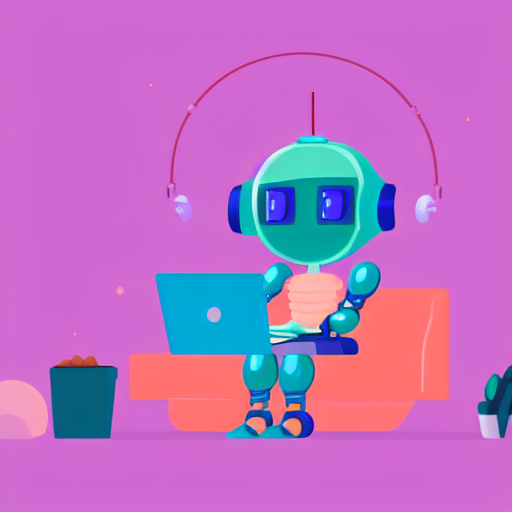

In [32]:
def draw(prompt, negative = NEGATIVE, steps = 20, guidance = 7.5, seed = 0, width = 512, height = 512, pipeline = None, **kw):
    gen = torch.Generator('cpu').manual_seed(seed)
    return (pipeline or pipe)(prompt, negative_prompt = negative, num_inference_steps=steps,
                              guidance_scale=guidance, width = width, height=height,
                              generator = gen, **kw).images[0]

test_img = draw('a cute robot studying with a laptop, flat illustration, pastel colors', seed = 1)
test_img

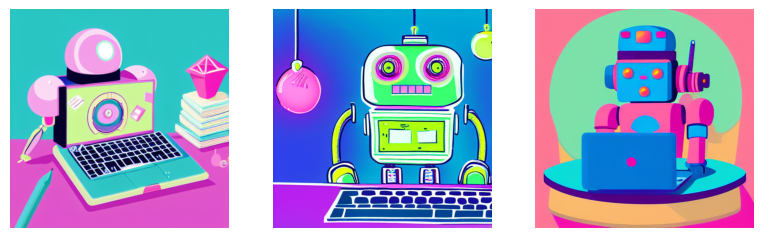

In [33]:
def make_prompt(korean_request):
    return chat([
        {'role': 'system', 'content': "You write prompts for Stable Diffusion, Convert the user's Korean request into ONE English prompt: "
         "comma-separated keywords, vivid style words, max 35 words. Output only the prompt."},
        {'role': 'user', 'content': korean_request}
    ], temperature = 0.4, max_tokens = 100).strip().strip('"')

request = '동아리 홍보 포스터에 쓸, 노트북으로 공부하는 귀여운 로봇 일러스트, 파스텔 색감.'
en_prompt = make_prompt(request)
show_images([draw(en_prompt, seed = s) for s in (3, 4, 5)])

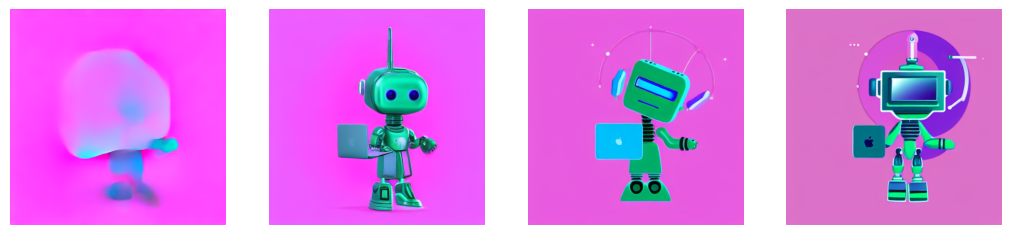

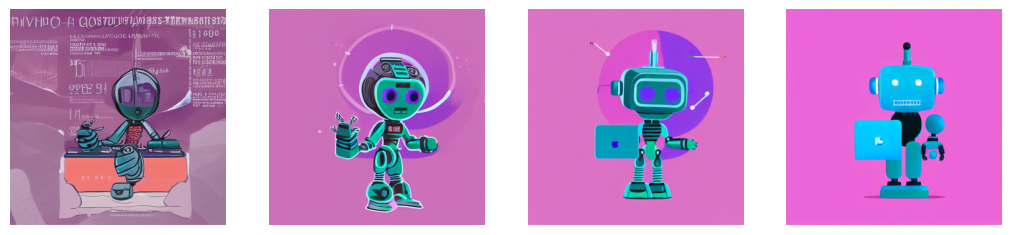

In [34]:
base_prompt = 'a friendly robot mascot holding a laptop, simple flat illustration, pastel colors'
show_images([draw(base_prompt, steps = s, seed = 1) for s in (2, 5, 10, 25)])
show_images([draw(base_prompt, guidance = g, seed = 1) for g in (1, 4, 7.5, 15)])